# picomake - wavenet :)

In [15]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import math
%matplotlib inline

In [16]:
# import the dataset

words = open("names.txt", 'r').read().split()
print("length of the dataset - ", len(words))

# build out the vocabulary

letters = sorted(set(letter for x in words for letter in x))
itos = {}
itos[0] = '.'
for number, character in enumerate(letters):
    itos[number+1] = character

stoi = {s:i for i,s in itos.items()}

# shuffle up the words
import random
random.seed(42)
random.shuffle(words)

length of the dataset -  32033


In [17]:
# build out the dataset 
context_size = 8

def build_dataset(words):
    X = []
    Y = []
    for word in words:
        context = [0]*context_size
        for ch in word + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix] # crop and append
            
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

n1 = int(0.8*len(words))
n2 = int(0.9*len(words))
Xtr,  Ytr  = build_dataset(words[:n1])     # 80%
Xdev, Ydev = build_dataset(words[n1:n2])   # 10%
Xte,  Yte  = build_dataset(words[n2:])     # 10%

torch.Size([182625, 8]) torch.Size([182625])
torch.Size([22655, 8]) torch.Size([22655])
torch.Size([22866, 8]) torch.Size([22866])


In [18]:
# pytorch code for init layers of the wavenet

class Linear:
    def __init__(self, fan_in, fan_out, bias = True):
        self.weight = torch.randn((fan_in, fan_out)) / fan_in**0.5
        self.bias = torch.zeros(fan_out) if bias else None

    def __call__(self, x):
        self.out = x@self.weight
        if self.bias is not None:
            self.out+=self.bias
        return self.out

    def parameters(self):
        if self.bias is not None:
            return [self.weight, self.bias]
        else:
            return [self.weight]

class BatchNorm1d:
    def __init__(self, dim, eps = 1e-5, momentum = 0.1):
        self.eps = eps # added to variance before sqrt
        self.momentum = momentum
        self.training = True

        #backprop parameters
        self.bngain = torch.ones(dim)
        self.bnbias = torch.zeros(dim)

        #self running parameters
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)

    def __call__(self, x):

        # calculate the forward pass
        if self.training:
            if x.ndim==2:
                dim = 0
            elif x.ndim==3:
                dim = (0,1)
            xmean = x.mean(dim, keepdim=True)
            xvar = x.var(dim, keepdim = True)
        else:
            xmean = self.running_mean
            xvar = self.running_var
        xhat = (x - xmean) / torch.sqrt(xvar + self.eps) #normalise to unit std deviation and zero mean
        self.out = self.bngain * xhat + self.bnbias

        # update running values

        if self.training:
            with torch.no_grad():
                self.running_mean = (1-self.momentum)*self.running_mean + self.momentum * xmean
                self.running_var = (1-self.momentum)*self.running_var + self.momentum * xvar
        return self.out

    def parameters(self):
        return [self.bnbias, self.bngain]

class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out
    def parameters(self):
        return []

class Embedding:

    def __init__(self, num_embeddings, embedding_dim):
        self.weight = torch.randn((num_embeddings, embedding_dim))
    def __call__(self, ix):
        self.out = self.weight[ix]
        return self.out
    def parameters(self):
        return [self.weight]

class FlattenConsecutive:
  
    def __init__(self, n):
        self.n = n
    
    def __call__(self, x):
        B, T, C = x.shape
        x = x.view(B, T//self.n, C*self.n)
        if x.shape[1] == 1:
            x = x.squeeze(1)
        self.out = x
        return self.out
  
    def parameters(self):
        return []

class Sequential:
  
    def __init__(self, layers):
        self.layers = layers
  
    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        self.out = x
        return self.out
    
    def parameters(self):
        # get parameters of all layers and stretch them out into one list
        return [p for layer in self.layers for p in layer.parameters()]

In [19]:
torch.manual_seed(42); # seed rng for reproducibility

In [20]:
# original network

n_embd = 24 # the dimensionality of the character embedding vectors
n_hidden = 200 # the number of neurons in the hidden layer of the MLP
vocab_size = 27
model = Sequential([
   Embedding(vocab_size, n_embd),
   FlattenConsecutive(2), Linear(n_embd * 2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
   FlattenConsecutive(2), Linear(n_hidden*2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
   FlattenConsecutive(2), Linear(n_hidden*2, n_hidden, bias=False), BatchNorm1d(n_hidden), Tanh(),
   Linear(n_hidden, vocab_size),
])

# parameter init
with torch.no_grad():
   model.layers[-1].weight *= 0.1 # last layer make less confident

parameters = model.parameters()
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
   p.requires_grad = True

176875


In [21]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []  

for i in range(max_steps):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (batch_size,))
  Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y
  
  # forward pass
  logits = model(Xb)
  loss = F.cross_entropy(logits, Yb) # loss function
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update: simple SGD
  lr = 0.1 if i < 150000 else 0.01 # step learning rate decay
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  if i % 10000 == 0: # print every once in a while
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())
print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')

      0/ 200000: 3.2902
  10000/ 200000: 2.4177
  20000/ 200000: 2.4491
  30000/ 200000: 2.0868
  40000/ 200000: 2.0755
  50000/ 200000: 1.9975
  60000/ 200000: 2.0083
  70000/ 200000: 1.9081
  80000/ 200000: 1.6850
  90000/ 200000: 2.0346
 100000/ 200000: 1.4587
 110000/ 200000: 1.7151
 120000/ 200000: 1.7884
 130000/ 200000: 1.8924
 140000/ 200000: 2.1367
 150000/ 200000: 1.5228
 160000/ 200000: 1.8994
 170000/ 200000: 2.0553
 180000/ 200000: 2.0986
 190000/ 200000: 1.8286
 199999/ 200000: 1.8027


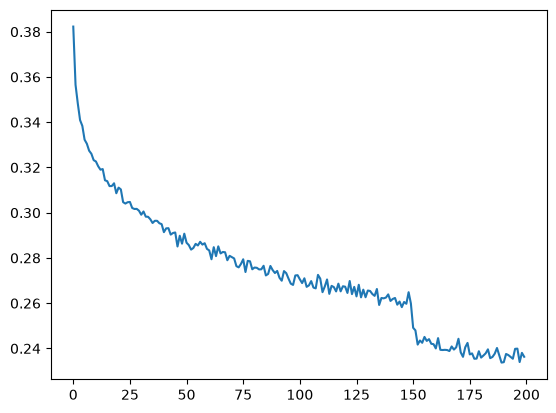

In [22]:
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1))

In [23]:
# put layers into eval mode (needed for batchnorm especially)
for layer in model.layers:
  layer.training = False

In [24]:
# evaluate the loss
@torch.no_grad() # this decorator disables gradient tracking inside pytorch
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  logits = model(x)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 1.6982251405715942
val 1.999804973602295


In [25]:
# sample from the model
for _ in range(20):
    
    out = []
    context = [0] * context_size # initialize with all ...
    while True:
      # forward pass the neural net
      logits = model(torch.tensor([context]))
      probs = F.softmax(logits, dim=1)
      # sample from the distribution
      ix = torch.multinomial(probs, num_samples=1).item()
      # shift the context window and track the samples
      context = context[1:] + [ix]
      out.append(ix)
      # if we sample the special '.' token, break
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out)) # decode and print the generated word

nikol.
bronet.
elana.
nayaan.
eysin.
jazzlyn.
reverlyn.
irleigh.
naseard.
jaylani.
alleya.
maria.
ainlon.
jaeleine.
kendre.
annamar.
lunaven.
eve.
galiana.
hender.


#### loss analysis

<small>

karpathy's network is bigger, with 300 neurons in every linear layer. mine is just 200. everything else including the lr decay, batchnorm specifics, epochs, etc are all identical. could break the 1.9 barrier with a bigger context size and probably more layers. even some l2 reg could help. but overfitting would mean generating one to one copies of the names in the dataset. which we dont really want?

such fun :)
</small>